In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [16]:
class QuadState(TypedDict) :
    a : int
    b : int
    c : int

    d : float
    equation : str
    result : str

In [17]:
def show_equation(state : QuadState) :
    equation = f'{state["a"]}x2 + {state["b"]}x + {state["c"]}'

    return {'equation' : equation}

In [18]:
def calc_desc(state : QuadState) :
    d = state['b']**2 - 4*state['a']*state['c']

    return { 'd' : d }

In [21]:
def real_roots(state : QuadState) :
    r1 = (-state['b'] + state['d'] ** 0.5)/(2*state['a'])
    r2 = (-state['b'] - state['d'] ** 0.5)/(2*state['a'])

    result = f'The roots are r1 : {r1} and r2 : {r2}'

    return {'result' : result}

In [22]:
def repeated_roots(state : QuadState) :
    r = (-state['b'])/(2*state['a'])

    result = f'Only repeating root is r : {r}'

    return {'result' : result}

In [23]:
def no_real_roots(state : QuadState) :
    result = f'No real roots'

    return {'result' : result}

In [24]:
def check_condition(state : QuadState) -> Literal['real_roots', 'no_real_roots', 'repeated_roots'] :
    if state['d'] < 0 :
        return 'no_real_roots'
    elif state['d'] > 0 :
        return 'real_roots'
    else :
        return 'repeated_roots'

In [25]:
graph = StateGraph(QuadState)

graph.add_node('Equation', show_equation)
graph.add_node('Descriminant', calc_desc)
graph.add_node('real_roots', real_roots)
graph.add_node('no_real_roots', no_real_roots)
graph.add_node('repeated_roots', repeated_roots)

graph.add_edge(START, 'Equation')
graph.add_edge('Equation', 'Descriminant')

graph.add_conditional_edges('Descriminant', check_condition)

graph.add_edge('real_roots', END)
graph.add_edge('no_real_roots', END)
graph.add_edge('repeated_roots', END)

workflow = graph.compile()

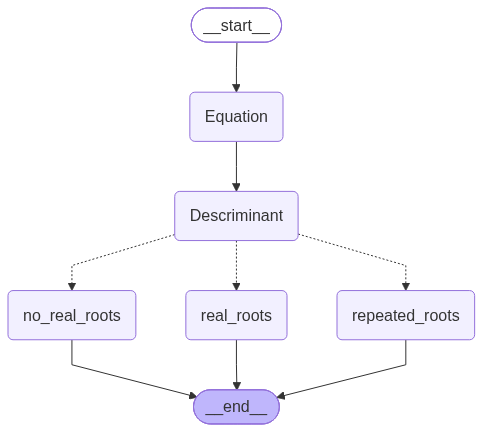

In [26]:
workflow

In [30]:
initial_state = {
    'a' : 1,
    'b' : 4,
    'c' : 3
}

workflow.invoke(initial_state)

{'a': 1,
 'b': 4,
 'c': 3,
 'd': 4,
 'equation': '1x2 + 4x + 3',
 'result': 'The roots are r1 : -1.0 and r2 : -3.0'}